--- YOUR DATASET ---
 X_Feature  Y_Target
  0.580836  0.454828
  1.559945  1.108453
  1.560186  0.907260
  3.745401 -0.660928
  5.986585 -0.243878
  6.011150 -0.651348
  7.080726  0.370657
  7.319939  0.748299
  8.661761  0.488539
  9.507143 -0.019423

Plotting the lines now...


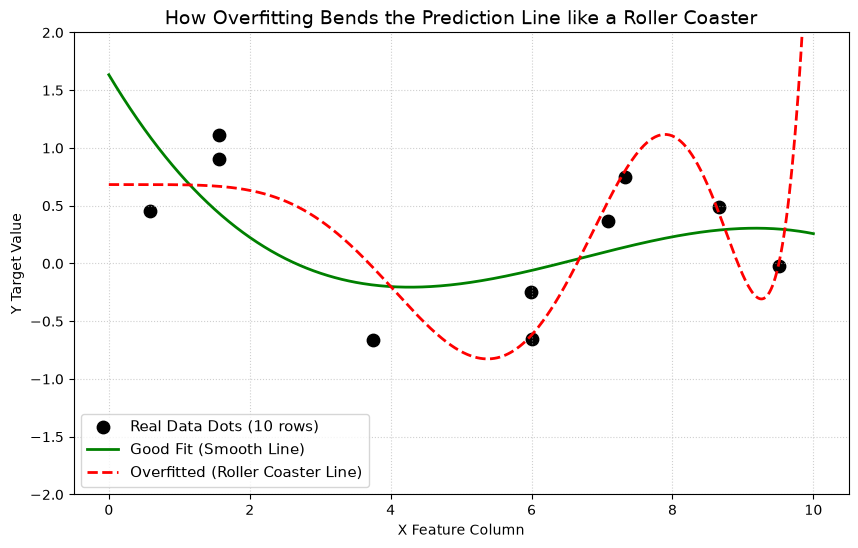

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# 1. Create a tiny dataset (10 rows)
np.random.seed(42)
X = np.sort(np.random.rand(10, 1) * 10, axis=0)
# True pattern is a smooth wave (sine wave) + some random noise
y = np.sin(X).ravel() + np.random.normal(0, 0.2, X.shape[0])

# Print the dataset to the console
df = pd.DataFrame({'X_Feature': X.ravel(), 'Y_Target': y})
print("--- YOUR DATASET ---")
print(df.to_string(index=False))
print("\nPlotting the lines now...")

# Generate points along the X axis to draw smooth lines
X_line = np.linspace(0, 10, 500)[:, np.newaxis]

# 2. Train a GOOD Model (Smooth, general line using 3 polynomial columns)
model_good = make_pipeline(PolynomialFeatures(degree=3), LinearRegression())
model_good.fit(X, y)
y_good = model_good.predict(X_line)

# 3. Train an OVERFITTED Model (Roller coaster line using 9 polynomial columns)
# Because we have 10 data points, a degree of 9 allows it to cross every dot perfectly!
model_overfit = make_pipeline(PolynomialFeatures(degree=9), LinearRegression())
model_overfit.fit(X, y)
y_overfit = model_overfit.predict(X_line)

# 4. Create the Visual Plot
plt.figure(figsize=(10, 6))

# Plot the real data points as black dots
plt.scatter(X, y, color='black', s=80, label='Real Data Dots (10 rows)')

# Plot the good smooth model
plt.plot(X_line, y_good, color='green', linewidth=2, label='Good Fit (Smooth Line)')

# Plot the overfitted roller coaster model
plt.plot(X_line, y_overfit, color='red', linewidth=2, linestyle='--', label='Overfitted (Roller Coaster Line)')

# Formatting the graph
plt.title('How Overfitting Bends the Prediction Line like a Roller Coaster', fontsize=14)
plt.xlabel('X Feature Column')
plt.ylabel('Y Target Value')
plt.ylim(-2, 2) # Limit y-axis so the crazy overfitted spikes stay visible
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

# Display the window
plt.show()
